## 1. Setup and paths

Configure paths for Kaggle (competition) vs local. No full EDA here—only what we need for **validation design**.

In [ ]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
key = user_secrets.get_secret("wandb_key")

In [1]:
!wandb login

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


In [2]:
!pip install monai -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 37.2 MB/s eta 0:00:0000:0100:01


In [3]:
!ls /kaggle/input/datasets/vladimirsydor

lidc-classification-ct-scans


In [44]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
from typing import Iterable, Optional, Tuple, Union, Sequence, List

import nibabel as nib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pytorch_lightning as pl
import torchmetrics
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

import monai
import timm
from monai.data import CacheNTransDataset, CacheDataset, DataLoader

from monai.transforms import (
    MapTransform,
)
from monai.config import KeysCollection
from monai.utils import ensure_tuple_rep


from pytorch_lightning.callbacks import ModelCheckpoint, LearningRateMonitor
from pytorch_lightning.loggers import WandbLogger

from sklearn.utils.class_weight import compute_class_weight

In [5]:
# Data root: Kaggle input vs local
if Path("/kaggle/input").exists():
    DATA_DIR = Path("/kaggle/input/competitions/lidc-lung-nodule-classification")
else:
    DATA_DIR = Path()  # or set to your local path

train_path = DATA_DIR / "train.parquet"
test_path = DATA_DIR / "test.csv"
assert train_path.exists(), f"Train not found: {train_path}"
print("Train path:", train_path)
print("Test path:", test_path, "exists:", test_path.exists())

Train path: /kaggle/input/competitions/lidc-lung-nodule-classification/train.parquet
Test path: /kaggle/input/competitions/lidc-lung-nodule-classification/test.csv exists: True


### CT scans (volumes)

In [6]:
# Where are the CT scans? (Kaggle often uses a subfolder like "scans" or "nifti")
# List competition dir to find the scan folder if needed
if DATA_DIR.exists():
    subdirs = [d.name for d in DATA_DIR.iterdir() if d.is_dir()]
    print("Data dir contents:", list(DATA_DIR.iterdir())[:15], "\nSubdirs:", subdirs)

# Convention: one NIfTI per scan, path = SCANS_DIR / f"{image_id}.nii.gz"
SCANS_DIR = DATA_DIR / "scans"   # or DATA_DIR / "nifti" — adjust to actual competition layout
if not SCANS_DIR.exists():
    SCANS_DIR = Path("/kaggle/input/datasets/vladimirsydor/lidc-classification-ct-scans")
print("\nSCANS_DIR:", SCANS_DIR)

Data dir contents: [PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/sample_submission.csv'), PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/train.parquet'), PosixPath('/kaggle/input/competitions/lidc-lung-nodule-classification/test.csv')] 
Subdirs: []

SCANS_DIR: /kaggle/input/datasets/vladimirsydor/lidc-classification-ct-scans


![my brain](https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_3/images/LIDC_example.png)

In [7]:
# Build image path for each row: image_id -> path to 3D volume
def image_id_to_path(image_id, scans_dir=SCANS_DIR, suffix=".nii"):
    return Path(scans_dir) / f"{image_id}{suffix}"

# Your scans use .nii (use suffix=".nii.gz" if needed)
train_df = pd.read_parquet(train_path)  # reload so we have train_df before later cells
train_df["image_path"] = train_df["image_id"].apply(lambda x: image_id_to_path(x))

# Existence check
existing = train_df["image_path"].apply(lambda p: Path(p).exists())
print("Train: rows with existing scan file:", existing.sum(), "/", len(train_df))
if not existing.all():
    missing = train_df.loc[~existing, "image_id"].unique()
    print("Missing image_ids (first 10):", list(missing)[:10])

Train: rows with existing scan file: 1986 / 1986


In [8]:
# Sanity check: load one CT volume and verify shape vs bbox
try:
    import nibabel as nib
    row = train_df.iloc[0]
    path = Path(row["image_path"])
    if path.exists():
        img = nib.load(str(path))
        vol = img.get_fdata()
        shape = vol.shape
        bbox = np.array(row["bbox"], dtype=int)  # [x0, y0, z0, x1, y1, z1]
        in_bounds = (bbox[0] >= 0 and bbox[3] <= shape[0] and
                     bbox[1] >= 0 and bbox[4] <= shape[1] and
                     bbox[2] >= 0 and bbox[5] <= shape[2])
        print("Sample volume shape (x,y,z):", shape)
        print("Sample bbox [x0,y0,z0,x1,y1,z1]:", bbox.tolist())
        print("Bbox within volume:", in_bounds)
        print("Dtype, value range:", vol.dtype, float(vol.min()), "-", float(vol.max()))
    else:
        print("Sample path not found; run on Kaggle or set SCANS_DIR to your NIfTI folder.")
except Exception as e:
    print("Nibabel check failed (install nibabel if needed):", e)

Sample volume shape (x,y,z): (512, 512, 465)
Sample bbox [x0,y0,z0,x1,y1,z1]: [423, 258, 190, 425, 264, 193]
Bbox within volume: True
Dtype, value range: float64 -3024.0 - 1798.0


## 2. Data analysis for validation design

We need to answer:
- **Grouping**: Are there multiple nodules per patient or per scan? (If yes, we must split by group to avoid leakage.)
- **Labels**: How are classes distributed? (Drives stratified splits.)
- **Train vs test**: Same patients/scans in both? (Affects how well CV approximates LB.)

In [9]:
# train_df already loaded above (with image_path); load test metadata
test_df = pd.read_csv(test_path) if test_path.exists() else None

print("Train shape:", train_df.shape)
print("Train columns:", list(train_df.columns))
print()
if test_df is not None:
    print("Test shape:", test_df.shape)
    print("Test columns:", list(test_df.columns))

Train shape: (1986, 11)
Train columns: ['id', 'image_id', 'object_id', 'patient_id', 'series_name', 'study_id', 'segmentMap', 'bbox', 'label', 'label_id', 'image_path']

Test shape: (280, 7)
Test columns: ['id', 'image_id', 'object_id', 'patient_id', 'series_name', 'study_id', 'bbox']


In [10]:
# Grouping structure: one row = one nodule; multiple nodules per scan/patient
patients = train_df["patient_id"].nunique()
scans = train_df["image_id"].nunique()
nodules = len(train_df)

print("Unique patients:", patients)
print("Unique scans (image_id):", scans)
print("Total nodules (rows):", nodules)
print()
print("Nodules per patient (min, median, max):", 
      train_df.groupby("patient_id").size().agg(["min", "median", "max"]).tolist())
print("Nodules per scan (min, median, max):",
      train_df.groupby("image_id").size().agg(["min", "median", "max"]).tolist())

Unique patients: 680
Unique scans (image_id): 680
Total nodules (rows): 1986

Nodules per patient (min, median, max): [1.0, 2.0, 21.0]
Nodules per scan (min, median, max): [1.0, 2.0, 21.0]


In [11]:
# Label distribution (incl. Indeterminate) — needed for stratified splits
print("Label distribution (train):")
print(train_df["label"].value_counts().sort_index())
print()
print("label_id distribution:")
print(train_df["label_id"].value_counts().sort_index())
# For validation we typically exclude Indeterminate (label_id == -1) or treat separately
train_with_label = train_df[train_df["label_id"] >= 0]
print("\nRows with valid label (label_id >= 0):", len(train_with_label))
print("Class counts (valid only):", train_with_label["label_id"].value_counts().sort_index().to_dict())

Label distribution (train):
label
Highly Suspicious        131
Highly Unlikely          250
Indeterminate            918
Moderately Suspicious    269
Moderately Unlikely      418
Name: count, dtype: int64

label_id distribution:
label_id
-1    918
 0    250
 1    418
 2    269
 3    131
Name: count, dtype: int64

Rows with valid label (label_id >= 0): 1068
Class counts (valid only): {0: 250, 1: 418, 2: 269, 3: 131}


In [12]:
# Train vs test overlap: do we share patients or scans? (affects CV–LB correlation)
if test_df is not None and "patient_id" in test_df.columns:
    train_patients = set(train_df["patient_id"].unique())
    test_patients = set(test_df["patient_id"].unique())
    overlap_patients = train_patients & test_patients
    print("Patients in train:", len(train_patients))
    print("Patients in test:", len(test_patients))
    print("Overlap (same patient in both):", len(overlap_patients))
if test_df is not None and "image_id" in test_df.columns:
    train_scans = set(train_df["image_id"].unique())
    test_scans = set(test_df["image_id"].unique())
    overlap_scans = train_scans & test_scans
    print("\nScans in train:", len(train_scans))
    print("Scans in test:", len(test_scans))
    print("Overlap (same scan in both):", len(overlap_scans))
if test_df is None:
    print("Test file not found; run on Kaggle to check train/test overlap.")

Patients in train: 680
Patients in test: 143
Overlap (same patient in both): 0

Scans in train: 680
Scans in test: 143
Overlap (same scan in both): 0


In [13]:
# Stratification feasibility: can we stratify by label within each group?
# If some patients have only one class, StratifiedGroupKFold may drop or warn
per_patient_labels = train_with_label.groupby("patient_id")["label_id"].nunique()
patients_single_class = (per_patient_labels == 1).sum()
patients_multi_class = (per_patient_labels > 1).sum()
print("Patients with only one class (nodules):", patients_single_class)
print("Patients with multiple classes:", patients_multi_class)
print("Feasible for StratifiedGroupKFold by patient_id:", "yes (stratify by label, group by patient)")

Patients with only one class (nodules): 339
Patients with multiple classes: 180
Feasible for StratifiedGroupKFold by patient_id: yes (stratify by label, group by patient)


### Sample CT visualization

Inspect a few axial slices of a cropped nodule volume and animate the full crop as a GIF.

In [14]:
def show_nodule_slices(image_path, bbox, crop_size=(64, 64, 64), n_slices=8, n_cols=4):
    """Display n_slices evenly-spaced axial slices from the nodule crop."""
    img = nib.load(str(image_path))
    vol = img.get_fdata().astype(np.float32)

    x0, y0, z0, x1, y1, z1 = [int(v) for v in bbox]
    x0, x1 = sorted((x0, x1))
    y0, y1 = sorted((y0, y1))
    z0, z1 = sorted((z0, z1))

    cx, cy, cz = (x0 + x1) // 2, (y0 + y1) // 2, (z0 + z1) // 2
    hx, hy, hz = crop_size[0] // 2, crop_size[1] // 2, crop_size[2] // 2

    xs = slice(max(cx - hx, 0), min(cx + hx, vol.shape[0]))
    ys = slice(max(cy - hy, 0), min(cy + hy, vol.shape[1]))
    zs = slice(max(cz - hz, 0), min(cz + hz, vol.shape[2]))
    crop = vol[xs, ys, zs]

    bx0 = int(np.clip(x0 - xs.start, 0, crop.shape[0] - 1))
    bx1 = int(np.clip(x1 - xs.start, 0, crop.shape[0] - 1))
    by0 = int(np.clip(y0 - ys.start, 0, crop.shape[1] - 1))
    by1 = int(np.clip(y1 - ys.start, 0, crop.shape[1] - 1))
    bz0 = int(np.clip(z0 - zs.start, 0, crop.shape[2] - 1))
    bz1 = int(np.clip(z1 - zs.start, 0, crop.shape[2] - 1))

    # Clip to soft-tissue CT window, then normalize to [0, 1]
    crop = np.clip(crop, -1024, 700)
    crop = (crop - crop.min()) / (crop.max() - crop.min() + 1e-8)

    n_rows = (n_slices + n_cols - 1) // n_cols
    z_indices = np.linspace(0, crop.shape[2] - 1, n_slices, dtype=int)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 3))
    axes = np.atleast_1d(axes).flatten()

    for i, z_idx in enumerate(z_indices):
        axes[i].imshow(crop[:, :, z_idx].T, cmap="gray", origin="lower")
        axes[i].set_title(f"z = {z_idx}", fontsize=9)

        if bz0 <= z_idx <= bz1:
            rect = Rectangle(
                (bx0, by0),
                bx1 - bx0 + 1,
                by1 - by0 + 1,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
            axes[i].add_patch(rect)

        axes[i].axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    fig.suptitle(f"Nodule crop with bbox overlay - {n_slices} axial slices", fontsize=12)
    plt.tight_layout()
    plt.show()

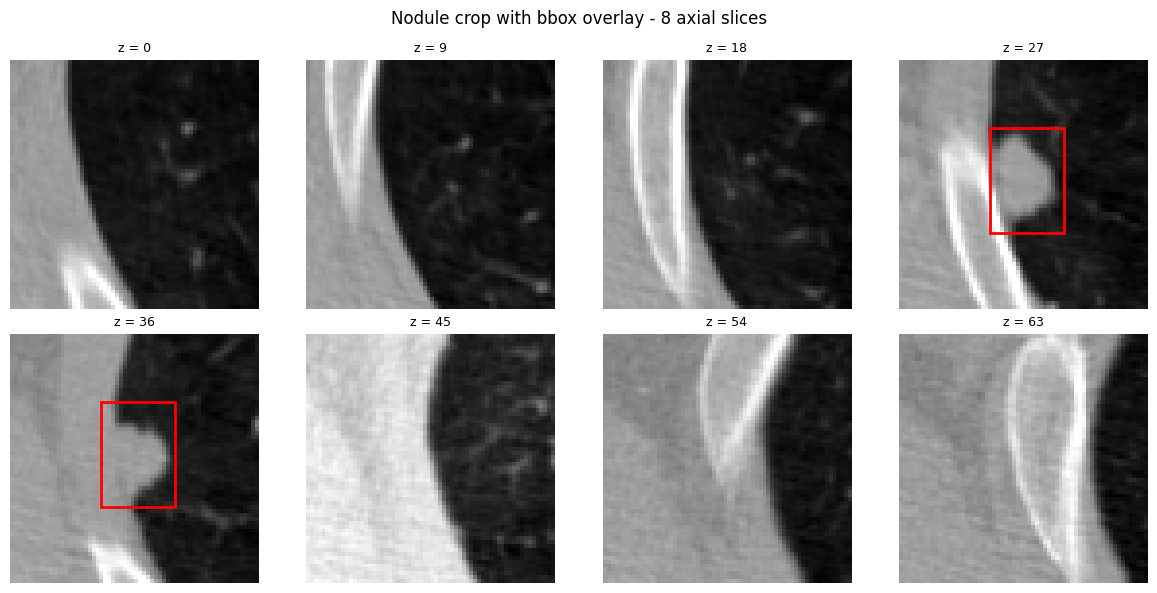

In [15]:
try:
    row = train_df.iloc[2]
    path = Path(row["image_path"])
    if path.exists():
        show_nodule_slices(path, row["bbox"])
    else:
        print("Scan not found locally. Run on Kaggle to see the visualization.")
except Exception as e:
    print("Visualization failed:", e)

In [16]:
def show_bbox_crop_gif(
    image_path: Union[str, Path],
    bbox_xyzxyz: Union[np.ndarray, Iterable[int]],
    name: str = "nodule",
    crop_size: Tuple[int, int, int] = (64, 64, 64),  # (sx, sy, sz) in voxels
    axis: int = 2,                                   # 0=x, 1=y, 2=z
    fps: int = 8,
    rotate_k: int = 0,                               # np.rot90 per frame (0..3)
    vmin: Optional[float] = None,
    vmax: Optional[float] = None,
    figsize: Tuple[float, float] = (5.5, 5.5),
    bbox_linewidth: float = 2.0,
) -> HTML:
    """
    Load NIfTI, take fixed-size crop around bbox center, animate slices,
    and overlay bbox only on slices that intersect the nodule.
    """
    image_path = Path(image_path)
    bbox = np.asarray(list(bbox_xyzxyz), dtype=int)
    if bbox.shape != (6,):
        raise ValueError(f"bbox_xyzxyz must be 6 ints [x0,y0,z0,x1,y1,z1], got {bbox.shape}")

    # 1) Load
    img = nib.load(str(image_path))
    vol = np.asanyarray(img.dataobj)
    if vol.ndim > 3:
        vol = vol[..., 0]
    sx, sy, sz = vol.shape[:3]

    # normalize + clip bbox to volume
    x0, y0, z0, x1, y1, z1 = bbox.tolist()
    x0, x1 = sorted((x0, x1))
    y0, y1 = sorted((y0, y1))
    z0, z1 = sorted((z0, z1))

    x0 = int(np.clip(x0, 0, sx - 1)); x1 = int(np.clip(x1, 0, sx - 1))
    y0 = int(np.clip(y0, 0, sy - 1)); y1 = int(np.clip(y1, 0, sy - 1))
    z0 = int(np.clip(z0, 0, sz - 1)); z1 = int(np.clip(z1, 0, sz - 1))

    # center
    cx = (x0 + x1) / 2.0
    cy = (y0 + y1) / 2.0
    cz = (z0 + z1) / 2.0

    # 2) fixed-size crop around center (pad if needed)
    csx, csy, csz = map(int, crop_size)
    hx, hy, hz = csx // 2, csy // 2, csz // 2

    xs0 = int(np.round(cx)) - hx
    ys0 = int(np.round(cy)) - hy
    zs0 = int(np.round(cz)) - hz
    xs1 = xs0 + csx
    ys1 = ys0 + csy
    zs1 = zs0 + csz

    xs_i, xs_e = max(xs0, 0), min(xs1, sx)
    ys_i, ys_e = max(ys0, 0), min(ys1, sy)
    zs_i, zs_e = max(zs0, 0), min(zs1, sz)

    crop = vol[xs_i:xs_e, ys_i:ys_e, zs_i:zs_e].astype(np.float32)

    pad_before_x = xs_i - xs0
    pad_before_y = ys_i - ys0
    pad_before_z = zs_i - zs0
    pad_after_x = xs1 - xs_e
    pad_after_y = ys1 - ys_e
    pad_after_z = zs1 - zs_e

    pad_width = (
        (pad_before_x, pad_after_x),
        (pad_before_y, pad_after_y),
        (pad_before_z, pad_after_z),
    )
    if any(p > 0 for pair in pad_width for p in pair):
        fill = float(np.min(crop)) if crop.size else 0.0
        crop = np.pad(crop, pad_width, mode="constant", constant_values=fill)

    if crop.shape != (csx, csy, csz):
        raise RuntimeError(f"Crop shape {crop.shape} != requested {crop_size}")

    # bbox coords in crop space (shift by crop origin in source volume: xs0,ys0,zs0)
    bx0 = int(np.clip(x0 - xs0, 0, csx - 1)); bx1 = int(np.clip(x1 - xs0, 0, csx - 1))
    by0 = int(np.clip(y0 - ys0, 0, csy - 1)); by1 = int(np.clip(y1 - ys0, 0, csy - 1))
    bz0 = int(np.clip(z0 - zs0, 0, csz - 1)); bz1 = int(np.clip(z1 - zs0, 0, csz - 1))

    # intensity window
    if vmin is None or vmax is None:
        lo, hi = np.percentile(crop, [1, 99])
        vmin = lo if vmin is None else vmin
        vmax = hi if vmax is None else vmax

    if axis not in (0, 1, 2):
        raise ValueError("axis must be 0 (x), 1 (y), or 2 (z)")

    n_frames = crop.shape[axis]
    if n_frames < 2:
        raise ValueError(f"Not enough frames along axis={axis} (n_frames={n_frames}).")

    # --- helpers for rectangle rotation ---
    def rot_rect(rect, orig_shape, k):
        """Rotate rect (x,y,w,h) defined in (col,row) coords along with rot90 k times CCW."""
        x, y, w, h = rect
        corners = np.array(
            [[x, y], [x + w - 1, y], [x, y + h - 1], [x + w - 1, y + h - 1]],
            dtype=float,
        )
        H0, W0 = orig_shape  # rows, cols
        k = k % 4
        if k == 0:
            new = corners
        elif k == 1:
            new = np.stack([corners[:, 1], (W0 - 1) - corners[:, 0]], axis=1)
        elif k == 2:
            new = np.stack([(W0 - 1) - corners[:, 0], (H0 - 1) - corners[:, 1]], axis=1)
        else:
            new = np.stack([(H0 - 1) - corners[:, 1], corners[:, 0]], axis=1)

        x_min, y_min = new.min(axis=0)
        x_max, y_max = new.max(axis=0)
        return (float(x_min), float(y_min), float(x_max - x_min + 1), float(y_max - y_min + 1))

    # slice extraction + rect (only if intersects bbox along axis)
    def frame_and_rect(i: int):
        # determine if current slice intersects bbox along chosen axis
        if axis == 2:
            intersects = (bz0 <= i <= bz1)
            frame0 = crop[:, :, i]
            rect0 = (by0, bx0, (by1 - by0 + 1), (bx1 - bx0 + 1))  # (col=y, row=x)
        elif axis == 1:
            intersects = (by0 <= i <= by1)
            frame0 = crop[:, i, :]
            rect0 = (bz0, bx0, (bz1 - bz0 + 1), (bx1 - bx0 + 1))  # (col=z, row=x)
        else:
            intersects = (bx0 <= i <= bx1)
            frame0 = crop[i, :, :]
            rect0 = (bz0, by0, (bz1 - bz0 + 1), (by1 - by0 + 1))  # (col=z, row=y)

        frame0 = np.asarray(frame0, dtype=np.float32)
        frame = np.rot90(frame0, k=rotate_k % 4) if (rotate_k % 4) else frame0

        if not intersects:
            return frame, None  # <-- this makes bbox disappear

        rect = rot_rect(rect0, frame0.shape, rotate_k)
        return frame, rect

    # --- plot ---
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    ax.set_title(f"{name} | crop={crop_size} | axis={axis} | {image_path.name[:10]}...", fontsize=10)

    frame0, rect0 = frame_and_rect(0)
    im = ax.imshow(frame0, cmap="gray", vmin=vmin, vmax=vmax)

    rect_patch = Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", linewidth=bbox_linewidth)
    ax.add_patch(rect_patch)

    txt = ax.text(
        0.02, 0.98, "", color="white", transform=ax.transAxes,
        va="top", ha="left", fontsize=10
    )

    interval_ms = int(1000 / max(1, fps))

    def update(i: int):
        frame, rect = frame_and_rect(i)
        im.set_data(frame)

        if rect is None:
            rect_patch.set_visible(False)
        else:
            rect_patch.set_visible(True)
            rect_patch.set_xy((rect[0], rect[1]))
            rect_patch.set_width(rect[2])
            rect_patch.set_height(rect[3])

        txt.set_text(f"slice {i+1}/{n_frames}")
        return im, rect_patch, txt

    anim = FuncAnimation(fig, update, frames=n_frames, interval=interval_ms, blit=False)
    plt.close(fig)

    return HTML(anim.to_jshtml())

In [17]:
sample_id = 1

show_bbox_crop_gif(
    image_path=train_df.iloc[sample_id]["image_path"],
    bbox_xyzxyz=train_df.iloc[sample_id]["bbox"],
    name="Example nodule",
    crop_size=(64, 64, 64),
    axis=1,
    fps=8,
    rotate_k=0,
)

## 3. Validation strategy 


- **Group by `patient_id`** so the same patient never appears in both train and val (avoids leakage; multiple nodules per patient).
- **Stratify by `label_id`** (on rows with `label_id >= 0`) so each fold keeps similar class distribution.
- Use **fixed seed** and **same splits for all experiments** so CV is comparable across models.

In [18]:
# StratifiedGroupKFold: same splits for all experiments
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS = 5
RANDOM_STATE = 42

# Only rows with valid labels (exclude Indeterminate)
train_valid = train_df[train_df["label_id"] >= 0].copy()
train_df["fold"] = -1  # -1 = Indeterminate (unused in CV)

sgk = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
for fold_num, (train_idx, val_idx) in enumerate(sgk.split(
    train_valid, train_valid["label_id"], train_valid["patient_id"]
)):
    # val_idx are indices into train_valid; map back to train_df
    train_df.loc[train_valid.index[val_idx], "fold"] = fold_num

# Summary
print("Fold assignment (valid rows only):")
print(train_df[train_df["fold"] >= 0]["fold"].value_counts().sort_index())
print("\nTrain/val sizes per fold (example fold 0):")
f0_val = train_df["fold"] == 0
f0_train = (train_df["fold"] >= 0) & (train_df["fold"] != 0)
print("  Train:", f0_train.sum(), "  Val:", f0_val.sum())

Fold assignment (valid rows only):
fold
0    215
1    220
2    216
3    199
4    218
Name: count, dtype: int64

Train/val sizes per fold (example fold 0):
  Train: 853   Val: 215


**Using folds in training:** For fold `f`, train on `train_df[(train_df["fold"] >= 0) & (train_df["fold"] != f)]`, validate on `train_df[train_df["fold"] == f]`. Use the same `N_SPLITS` and `RANDOM_STATE` everywhere so all models share the same splits.

In [19]:
# Validation diagnostics: fold sizes and class balance
valid_df = train_df[train_df["fold"] >= 0].copy()

print("Fold sizes:")
print(valid_df["fold"].value_counts().sort_index())
print()

fold_class_counts = (
    valid_df.groupby(["fold", "label_id"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
print("Class counts per fold:")
print(fold_class_counts)
print()

fold_class_ratio = fold_class_counts.div(fold_class_counts.sum(axis=1), axis=0)
print("Class ratios per fold:")
print(fold_class_ratio.round(3))

Fold sizes:
fold
0    215
1    220
2    216
3    199
4    218
Name: count, dtype: int64

Class counts per fold:
label_id   0   1   2   3
fold                    
0         56  90  46  23
1         42  92  60  26
2         55  78  62  21
3         47  73  48  31
4         50  85  53  30

Class ratios per fold:
label_id      0      1      2      3
fold                                
0         0.260  0.419  0.214  0.107
1         0.191  0.418  0.273  0.118
2         0.255  0.361  0.287  0.097
3         0.236  0.367  0.241  0.156
4         0.229  0.390  0.243  0.138


In [20]:
# Leakage checks: patient-level and optional scan-level
for f in sorted(valid_df["fold"].unique()):
    tr_patients = set(valid_df.loc[valid_df["fold"] != f, "patient_id"])
    va_patients = set(valid_df.loc[valid_df["fold"] == f, "patient_id"])
    assert len(tr_patients & va_patients) == 0, f"Leakage in fold {f} by patient_id"
print("No patient leakage across all folds.")

if "image_id" in valid_df.columns:
    for f in sorted(valid_df["fold"].unique()):
        tr_scans = set(valid_df.loc[valid_df["fold"] != f, "image_id"])
        va_scans = set(valid_df.loc[valid_df["fold"] == f, "image_id"])
        assert len(tr_scans & va_scans) == 0, f"Leakage in fold {f} by image_id"
    print("No scan leakage across all folds.")

No patient leakage across all folds.
No scan leakage across all folds.


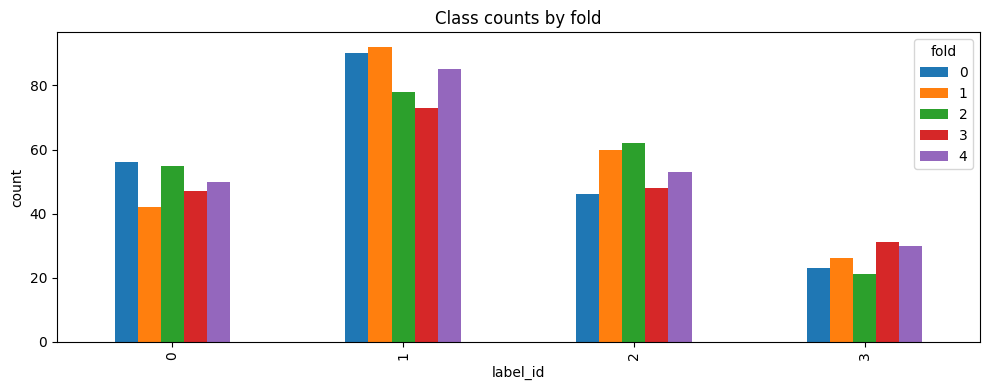

In [21]:
ax = fold_class_counts.T.plot(kind="bar", figsize=(10, 4))
ax.set_title("Class counts by fold")
ax.set_xlabel("label_id")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

## Validation strategy motivation and expected LB correlation

We use StratifiedGroupKFold with:

- groups = patient_id
- stratification target = label_id
- fixed random_state for reproducibility
- only rows with label_id >= 0 for supervised CV

Motivation:

- Grouping by patient_id prevents leakage across folds because multiple nodules can come from the same patient.
- Stratification by label_id stabilizes class distribution per fold and reduces metric variance.
- Fixed folds allow fair model-to-model comparison.

Expected correlation with Public LB:

- Likely moderate-to-high if train/test come from similar acquisition pipelines and patient distributions.
- Lower correlation can happen due to domain shift, annotation noise, hidden test distribution differences, and overfitting to CV.


# SSL Pre-training (SimCLR attempt)

In [38]:
class CenterCropAroundBBoxd(MapTransform):
    """
    Crop a fixed-size 3D patch centered at the bbox center.
    Expects bbox in voxel coords: [x0, y0, z0, x1, y1, z1] (inclusive max is OK).

    Input dict must contain:
      - image key (e.g. "image") holding a tensor/ndarray with shape [C, X, Y, Z]
      - bbox_key (default "bbox") holding array-like length 6

    Output:
      - replaces image with cropped patch [C, crop_x, crop_y, crop_z]
      - also adds "bbox_in_crop" with bbox coords in crop space (clipped)
    """

    def __init__(
        self,
        keys: KeysCollection,
        bbox_key: str = "bbox",
        crop_size: Union[Sequence[int], int] = (64, 64, 64),
        pad_mode: str = "constant",
        pad_value: float = 0,  
        allow_missing_keys: bool = False,
    ):
        super().__init__(keys, allow_missing_keys)
        self.bbox_key = bbox_key
        self.crop_size = ensure_tuple_rep(crop_size, 3)
        self.pad_mode = pad_mode
        self.pad_value = pad_value

    @staticmethod
    def _clip_bbox(b: np.ndarray, shape_xyz: Tuple[int, int, int]) -> np.ndarray:
        sx, sy, sz = shape_xyz
        x0, y0, z0, x1, y1, z1 = b.tolist()
        x0, x1 = sorted((x0, x1))
        y0, y1 = sorted((y0, y1))
        z0, z1 = sorted((z0, z1))
        x0 = int(np.clip(x0, 0, sx - 1)); x1 = int(np.clip(x1, 0, sx - 1))
        y0 = int(np.clip(y0, 0, sy - 1)); y1 = int(np.clip(y1, 0, sy - 1))
        z0 = int(np.clip(z0, 0, sz - 1)); z1 = int(np.clip(z1, 0, sz - 1))
        return np.array([x0, y0, z0, x1, y1, z1], dtype=int)

    def __call__(self, data):
        d = dict(data)

        if self.bbox_key not in d:
            raise KeyError(f"Missing '{self.bbox_key}' in data dict. Provide bbox as [x0,y0,z0,x1,y1,z1].")

        bbox = np.asarray(d[self.bbox_key], dtype=int).reshape(-1)
        if bbox.shape[0] != 6:
            raise ValueError(f"bbox must have 6 values [x0,y0,z0,x1,y1,z1], got shape {bbox.shape}")

        for k in self.keys:
            img = d[k]
            # Expect [C, X, Y, Z]
            if img.ndim != 4:
                raise ValueError(f"Expected image '{k}' with shape [C,X,Y,Z], got {tuple(img.shape)}")

            C, X, Y, Z = img.shape
            bbox_c = self._clip_bbox(bbox, (X, Y, Z))
            x0, y0, z0, x1, y1, z1 = bbox_c.tolist()

            # center of bbox (voxel space)
            cx = (x0 + x1) / 2.0
            cy = (y0 + y1) / 2.0
            cz = (z0 + z1) / 2.0

            sx, sy, sz = self.crop_size
            hx, hy, hz = sx // 2, sy // 2, sz // 2

            # crop bounds in source volume (half-open)
            xs0 = int(np.round(cx)) - hx
            ys0 = int(np.round(cy)) - hy
            zs0 = int(np.round(cz)) - hz
            xs1 = xs0 + sx
            ys1 = ys0 + sy
            zs1 = zs0 + sz

            # intersection with image
            xi0, xi1 = max(xs0, 0), min(xs1, X)
            yi0, yi1 = max(ys0, 0), min(ys1, Y)
            zi0, zi1 = max(zs0, 0), min(zs1, Z)

            crop = img[:, xi0:xi1, yi0:yi1, zi0:zi1]

            # padding amounts
            pad_before_x = xi0 - xs0
            pad_before_y = yi0 - ys0
            pad_before_z = zi0 - zs0
            pad_after_x = xs1 - xi1
            pad_after_y = ys1 - yi1
            pad_after_z = zs1 - zi1

            # MONAI images are often torch tensors; use np.pad only if numpy
            is_torch = hasattr(crop, "detach") and hasattr(crop, "cpu")
            if is_torch:
                import torch
                pad = (pad_before_z, pad_after_z, pad_before_y, pad_after_y, pad_before_x, pad_after_x)  # reverse order
                crop = torch.nn.functional.pad(
                    crop,
                    pad=pad,
                    mode="constant" if self.pad_mode == "constant" else self.pad_mode,
                    value=self.pad_value,
                )
            else:
                crop = np.pad(
                    crop,
                    pad_width=((0, 0),
                               (pad_before_x, pad_after_x),
                               (pad_before_y, pad_after_y),
                               (pad_before_z, pad_after_z)),
                    mode=self.pad_mode,
                    constant_values=self.pad_value if self.pad_mode == "constant" else 0,
                )

            # bbox mapped into crop space (clipped)
            bx0 = int(np.clip(x0 - xs0, 0, sx - 1)); bx1 = int(np.clip(x1 - xs0, 0, sx - 1))
            by0 = int(np.clip(y0 - ys0, 0, sy - 1)); by1 = int(np.clip(y1 - ys0, 0, sy - 1))
            bz0 = int(np.clip(z0 - zs0, 0, sz - 1)); bz1 = int(np.clip(z1 - zs0, 0, sz - 1))

            d[k] = crop
            d["bbox_in_crop"] = np.array([bx0, by0, bz0, bx1, by1, bz1], dtype=int)
            d["crop_origin_xyz"] = np.array([xs0, ys0, zs0], dtype=int)  # useful for debugging

        return d

In [45]:
base_transform = monai.transforms.Compose([
    monai.transforms.LoadImaged(keys=["image"], dtype="float32"),
    monai.transforms.EnsureChannelFirstd(keys=["image"], channel_dim="no_channel"),
    CenterCropAroundBBoxd(
        keys=["image"], bbox_key="bbox", crop_size=CROP_SIZE,
        pad_mode="constant", pad_value=-1024.0,
    ),
    monai.transforms.ScaleIntensityRanged(
        keys=["image"], a_min=-1024, a_max=700.0, b_min=0.0, b_max=1.0, clip=True,
    )
])

ssl_data_dicts = []
for _, row in ssl_df.iterrows():
    ssl_data_dicts.append({
        "image": str(row["image_path"]),
        "bbox": np.array(row["bbox"], dtype=np.int64)
    })

cached_dataset = CacheDataset(
    data=ssl_data_dicts, 
    transform=base_transform, 
    cache_rate=1.0, 
    num_workers=4   
)

ssl_augs = monai.transforms.Compose([
    monai.transforms.RandFlip(prob=0.5, spatial_axis=0),
    monai.transforms.RandFlip(prob=0.5, spatial_axis=1),
    monai.transforms.RandFlip(prob=0.5, spatial_axis=2),
    monai.transforms.RandRotate90(prob=0.5, max_k=3, spatial_axes=(0, 1)),
    monai.transforms.RandZoom(prob=0.3, min_zoom=0.8, max_zoom=1.2, mode="trilinear"),
    monai.transforms.RandGaussianNoise(prob=0.2, mean=0.0, std=0.05),
])

Loading dataset: 100%|██████████| 1986/1986 [15:00<00:00,  2.21it/s]


In [46]:
class SSLMultiViewDataset(torch.utils.data.Dataset):
    def __init__(self, cached_base_dataset, aug_transform, n_views=2):
        self.cached_dataset = cached_base_dataset
        self.aug_transform = aug_transform
        self.n_views = n_views

    def __len__(self):
        return len(self.cached_dataset)

    def __getitem__(self, idx):
        base_item = self.cached_dataset[idx]
        base_tensor = base_item["image"] # (1, 64, 64, 64)
        
        views = []
        for _ in range(self.n_views):
            views.append(self.aug_transform(base_tensor))
            
        return tuple(views)

In [51]:
# Use all available training data for self-supervised pre-training (ignoring labels)
ssl_df = train_df.copy()
ssl_dataset = SSLMultiViewDataset(cached_dataset, ssl_augs, n_views=2)
ssl_loader = DataLoader(ssl_dataset, batch_size=16, shuffle=True, num_workers=4, drop_last=True)

## 4.2. SimCLR Architecture & Lightning Module

In [ ]:
class SimCLR_3D(pl.LightningModule):
    def __init__(self, temperature=0.1, lr=1e-3, weight_decay=1e-4):
        super().__init__()
        self.save_hyperparameters()
        
        # 2D ResNet encoder from MONAI
        self.encoder = resnet18(spatial_dims=3, n_input_channels=1, num_classes=512)
        # Projection head
        self.projector = nn.Sequential(
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Linear(512, 128)
        )

    def forward(self, x):
        features = self.encoder(x)
        return features

    def nt_xent_loss(self, z1, z2):
        batch_size = z1.size(0)
        z = torch.cat([z1, z2], dim=0)
        z = F.normalize(z, dim=1)
        
        # Similarity matrix
        sim_matrix = torch.matmul(z, z.T) / self.hparams.temperature
        
        # Mask out self-similarity
        mask = torch.eye(2 * batch_size, dtype=torch.bool, device=self.device)
        sim_matrix.masked_fill_(mask, -9e15)

        # Labels for positive pairs: z1_i matches z2_i
        labels = torch.cat([
            torch.arange(batch_size, 2 * batch_size, device=self.device),
            torch.arange(0, batch_size, device=self.device)
        ])
        
        loss = F.cross_entropy(sim_matrix, labels)
        return loss

    def training_step(self, batch, batch_idx):
        view1 = batch[0]
        view2 = batch[1]
        
        z1 = self.projector(self.encoder(view1))
        z2 = self.projector(self.encoder(view2))
        
        loss = self.nt_xent_loss(z1, z2)
        self.log("train_ssl_loss", loss, prog_bar=True)
        return loss

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            self.parameters(), 
            lr=self.hparams.lr, 
            weight_decay=self.hparams.weight_decay
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)
        return [optimizer], [scheduler]

In [49]:
logger = WandbLogger(project="lidc-simclr-ssl", name="simclr-run1")

## 4.3. Run SSL Pre-training

In [ ]:
ssl_model = SimCLR_3D(temperature=0.1, lr=3e-4)

trainer_ssl = pl.Trainer(
    max_epochs=5,
    accelerator="gpu",  
    devices=1,         
    log_every_n_steps=5,
    logger=logger,
    enable_checkpointing=True
)

trainer_ssl.fit(ssl_model, ssl_loader)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder   │ ResNet     │ 33.4 M │ train │     0 │
│ 1 │ projector │ Sequential │  329 K │ train │     0 │
└───┴───────────┴────────────┴────────┴───────┴───────┘

Trainable params: 33.8 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 33.8 M                                                                                               
Total estimated model params size (MB): 135                                                                        
Modules in train mode: 73                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=5` reached.


In [73]:
logger.experiment.finish()

epoch,▁▁▃▃▃▃▃▃▁▁▁▁▁▃▃▃▃▃▃▃▅▅▅▅▅▅▆▆▆▆▆▆▆██████▁
train_MulticlassF1Score,█▁
train_MulticlassPrecision,█▁
train_MulticlassRecall,█▁
train_loss_epoch,█▁
train_loss_step,▃█▁▁█
train_ssl_loss,█▇▃▃▂▁▂▁▁▂▂▂▂▂▂▃▂▂▁▁▁▂▂▂▂▁▁▁▁▁▂▂▂▁▁▁▁▁▂▁
trainer/global_step,▁▁▂▂▃▃▃▃▄▄▄▄▁▁▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▇▇▇████▄
val_MulticlassF1Score,█▁
val_MulticlassPrecision,█▁
+2,...


# Linear probing

## 5.1. Dataset & DataLoaders for Classification

In [ ]:
supervised_df = train_df[train_df["label_id"] >= 0].copy()

train_transforms = monai.transforms.Compose([
    monai.transforms.LoadImaged(keys=["image"], dtype="float32"),
    monai.transforms.EnsureChannelFirstd(keys=["image"], channel_dim="no_channel"),
    CenterCropAroundBBoxd(
        keys=["image"], bbox_key="bbox", crop_size=CROP_SIZE,
        pad_mode="constant", pad_value=-1024.0,
    ),
    monai.transforms.ScaleIntensityRanged(
        keys=["image"], a_min=-1024, a_max=700.0, b_min=0.0, b_max=1.0, clip=True,
    ),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=0),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=1),
    monai.transforms.RandFlipd(keys=["image"], prob=0.5, spatial_axis=2),
])

val_transforms = monai.transforms.Compose([
    monai.transforms.LoadImaged(keys=["image"], dtype="float32"),
    monai.transforms.EnsureChannelFirstd(keys=["image"], channel_dim="no_channel"),
    CenterCropAroundBBoxd(
        keys=["image"], bbox_key="bbox", crop_size=CROP_SIZE,
        pad_mode="constant", pad_value=-1024.0,
    ),
    monai.transforms.ScaleIntensityRanged(
        keys=["image"], a_min=-1024, a_max=700.0, b_min=0.0, b_max=1.0, clip=True,
    )
])

def get_downstream_dataloaders(df, fold=0, batch_size=16):
    train_split = df[df["fold"] != fold]
    val_split = df[df["fold"] == fold]
    
    def df_to_dicts(dataframe):
        return [{
            "image": str(row["image_path"]),
            "bbox": np.array(row["bbox"], dtype=np.int64),
            "label": row["label_id"]
        } for _, row in dataframe.iterrows()]
        
    train_ds = CacheDataset(data=df_to_dicts(train_split), transform=train_transforms, cache_rate=1.0, num_workers=4)
    val_ds = CacheDataset(data=df_to_dicts(val_split), transform=val_transforms, cache_rate=1.0, num_workers=4)
    
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=4, drop_last=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=4)
    
    return train_loader, val_loader

## 5.2. Downstream Lightning Module

In [ ]:
class SimCLR_Downstream_Classifier(pl.LightningModule):
    def __init__(
        self, 
        base_encoder, 
        n_classes=4, 
        lr=1e-3, 
        fine_tune=False,
        class_weights=None
    ):
        super().__init__()
        self.save_hyperparameters(ignore=['base_encoder'])
        
        self.encoder = base_encoder
        
        if not fine_tune:
            for param in self.encoder.parameters():
                param.requires_grad = False
                
        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(512, n_classes)
        )
        
        self.criterion = nn.CrossEntropyLoss(weight=class_weights)

        self.train_metrics = torchmetrics.MetricCollection(metrics=[
            torchmetrics.F1Score(task="multiclass", num_classes=n_classes, average="macro"),
            torchmetrics.Recall(task="multiclass", num_classes=n_classes, average="macro"),
            torchmetrics.Precision(task="multiclass", num_classes=n_classes, average="macro")
        ], prefix="train_")  
        
        self.val_metrics = torchmetrics.MetricCollection(metrics=[
            torchmetrics.F1Score(task="multiclass", num_classes=n_classes, average="macro"),
            torchmetrics.Recall(task="multiclass", num_classes=n_classes, average="macro"),
            torchmetrics.Precision(task="multiclass", num_classes=n_classes, average="macro")
        ], prefix="val_")

    def forward(self, x):
        features = self.encoder(x)
        logits = self.classifier(features)
        return logits

    def training_step(self, batch, batch_idx):
        x, y = batch["image"], batch["label"]
        logits = self(x)
        loss = self.criterion(logits, y)
        preds = logits.argmax(dim=-1)
        
        self.train_metrics.update(preds, y)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def on_train_epoch_end(self):
        self.log_dict(self.train_metrics.compute(), on_epoch=True)
        self.train_metrics.reset()

    def validation_step(self, batch, batch_idx):
        x, y = batch["image"], batch["label"]
        logits = self(x)
        loss = self.criterion(logits, y)
        preds = logits.argmax(dim=-1)
        
        self.val_metrics.update(preds, y)
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        self.log_dict(self.val_metrics.compute(), on_epoch=True)
        self.val_metrics.reset()

    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, self.parameters()), 
            lr=self.hparams.lr
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
        return [optimizer], [scheduler]

## 5.3. Train Classification (Linear Probing example)

In [ ]:
labels_np = supervised_df["label_id"].values
classes = np.unique(labels_np)
weights = compute_class_weight("balanced", classes=classes, y=labels_np)
class_weights = torch.tensor(weights, dtype=torch.float32)

FOLD = 0
train_loader_cls, val_loader_cls = get_downstream_dataloaders(supervised_df, fold=FOLD, batch_size=8)

In [74]:
classifier_model = SimCLR_Downstream_Classifier(
    base_encoder=ssl_model.encoder, 
    n_classes=4, 
    lr=1e-3, 
    fine_tune=False, 
    class_weights=class_weights
)

run_name = f"simclr-linear-probe-fold{FOLD}"
logger_cls = WandbLogger(project="lidc-simclr-ssl", name=run_name)

checkpoint_cb = ModelCheckpoint(
    monitor="val_MulticlassF1Score",
    mode="max",
    save_top_k=1,
    dirpath="checkpoints",
    filename=run_name + "-{epoch:02d}-{val_MulticlassF1Score:.4f}",
)

trainer_cls = pl.Trainer(
    max_epochs=10,
    accelerator="gpu",
    devices=1,
    logger=logger_cls,
    callbacks=[checkpoint_cb]
)


try:
    trainer_cls.fit(classifier_model, train_loader_cls, val_loader_cls)
except Exception as e:
    print(f"Error occurred: {e}")
finally:
    logger_cls.experiment.finish()

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder       │ ResNet           │ 33.4 M │ train │     0 │
│ 1 │ classifier    │ Sequential       │  2.1 K │ train │     0 │
│ 2 │ criterion     │ CrossEntropyLoss │      0 │ train │     0 │
│ 3 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 4 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 2.1 K                                                                                            
Non-trainable params: 33.4 M                                                                                       
Total params: 33.4 M                                                                                               
Total estimated model params size (MB): 133                                                                        
Modules in train mode: 80                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=10` reached.


epoch,▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇███
train_MulticlassF1Score,▁▄▃▃▆▆▇█▅▇
train_MulticlassPrecision,▁▄▃▃▇▇▇█▅▇
train_MulticlassRecall,▁▃▃▃▆▆▇█▆█
train_loss_epoch,█▅▆▅▅▂▃▁▂▁
train_loss_step,▁▁▁▃▄█▃▅▄▅▃▇▂▁▃▃▂▄▃▁▂
trainer/global_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███
val_MulticlassF1Score,▁▅▁█▂▆▃█▄▄
val_MulticlassPrecision,▄█▁█▆▅▅█▆▆
val_MulticlassRecall,▁▇█▆▃█▄█▆▆
+1,...
